In [68]:
import pandas as pd
import numpy as np

In [61]:
# import model
from sklearn.linear_model import LinearRegression

# for splitting
from sklearn.model_selection import train_test_split

# for scaling of data
from sklearn.preprocessing import StandardScaler

# import metrics
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [3]:
df=pd.read_csv('gold_price_data.csv')

In [4]:
df.head()

,Date,SPX,GLD,USO,SLV,EUR/USD
0,1/2/2008,1447.160034,84.860001,78.470001,15.180,1.471692
1,1/3/2008,1447.160034,85.570000,78.370003,15.285,1.474491
2,1/4/2008,1411.630005,85.129997,77.309998,15.167,1.475492
3,1/7/2008,1416.180054,84.769997,75.500000,15.053,1.468299
4,1/8/2008,1390.189941,86.779999,76.059998,15.590,1.557099


In [5]:
df.tail()

,Date,SPX,GLD,USO,SLV,EUR/USD
2285,5/8/2018,2671.919922,124.589996,14.0600,15.5100,1.186789
2286,5/9/2018,2697.790039,124.330002,14.3700,15.5300,1.184722
2287,5/10/2018,2723.070068,125.180000,14.4100,15.7400,1.191753
2288,5/14/2018,2730.129883,124.489998,14.3800,15.5600,1.193118
2289,5/16/2018,2725.780029,122.543800,14.4058,15.4542,1.182033


In [6]:
df.count()

Date       2290
SPX        2290
GLD        2290
USO        2290
SLV        2290
EUR/USD    2290
dtype: int64

In [7]:
df.isnull().sum()

Date       0
SPX        0
GLD        0
USO        0
SLV        0
EUR/USD    0
dtype: int64

In [8]:
df.isnull()

,Date,SPX,GLD,USO,SLV,EUR/USD
0,False,False,False,False,False,False
1,False,False,False,False,False,False
2,False,False,False,False,False,False
3,False,False,False,False,False,False
4,False,False,False,False,False,False
...,...,...,...,...,...,...
2285,False,False,False,False,False,False
2286,False,False,False,False,False,False
2287,False,False,False,False,False,False
2288,False,False,False,False,False,False


In [9]:
df['Date'].unique()

<ArrowStringArray>
[ '1/2/2008',  '1/3/2008',  '1/4/2008',  '1/7/2008',  '1/8/2008',  '1/9/2008',
 '1/10/2008', '1/11/2008', '1/14/2008', '1/15/2008',
 ...
 '4/30/2018',  '5/1/2018',  '5/2/2018',  '5/3/2018',  '5/7/2018',  '5/8/2018',
  '5/9/2018', '5/10/2018', '5/14/2018', '5/16/2018']
Length: 2290, dtype: str

In [10]:
df.columns

Index(['Date', 'SPX', 'GLD', 'USO', 'SLV', 'EUR/USD'], dtype='str')

In [11]:
df.dtypes

Date           str
SPX        float64
GLD        float64
USO        float64
SLV        float64
EUR/USD    float64
dtype: object

In [12]:
df.duplicated().sum()

np.int64(0)

In [13]:
df.duplicated()

0       False
1       False
2       False
3       False
4       False
        ...  
2285    False
2286    False
2287    False
2288    False
2289    False
Length: 2290, dtype: bool

In [14]:
df.describe()

,SPX,GLD,USO,SLV,EUR/USD
count,2290.000000,2290.000000,2290.000000,2290.000000,2290.000000
mean,1654.315776,122.732875,31.842221,20.084997,1.283653
std,519.111540,23.283346,19.523517,7.092566,0.131547
min,676.530029,70.000000,7.960000,8.850000,1.039047
25%,1239.874969,109.725000,14.380000,15.570000,1.171313
50%,1551.434998,120.580002,33.869999,17.268500,1.303297
75%,2073.010070,132.840004,37.827501,22.882500,1.369971
max,2872.870117,184.589996,117.480003,47.259998,1.598798


In [54]:
df['GLD'].skew()

np.float64(0.3341383472692508)

In [56]:
df['GLD'].median()

np.float64(120.580002)

In [15]:
df['Date']= pd.to_datetime(df['Date'])

In [36]:
df['Year']=df['Date'].dt.year

In [37]:
df.head()

,Date,SPX,GLD,USO,SLV,EUR/USD,Year
0,2008-01-02,1447.160034,84.860001,78.470001,15.180,1.471692,2008
1,2008-01-03,1447.160034,85.570000,78.370003,15.285,1.474491,2008
2,2008-01-04,1411.630005,85.129997,77.309998,15.167,1.475492,2008
3,2008-01-07,1416.180054,84.769997,75.500000,15.053,1.468299,2008
4,2008-01-08,1390.189941,86.779999,76.059998,15.590,1.557099,2008


In [17]:
df.dtypes

Date       datetime64[us]
SPX               float64
GLD               float64
USO               float64
SLV               float64
EUR/USD           float64
dtype: object

In [28]:
import matplotlib.pyplot as plt
import seaborn as sns

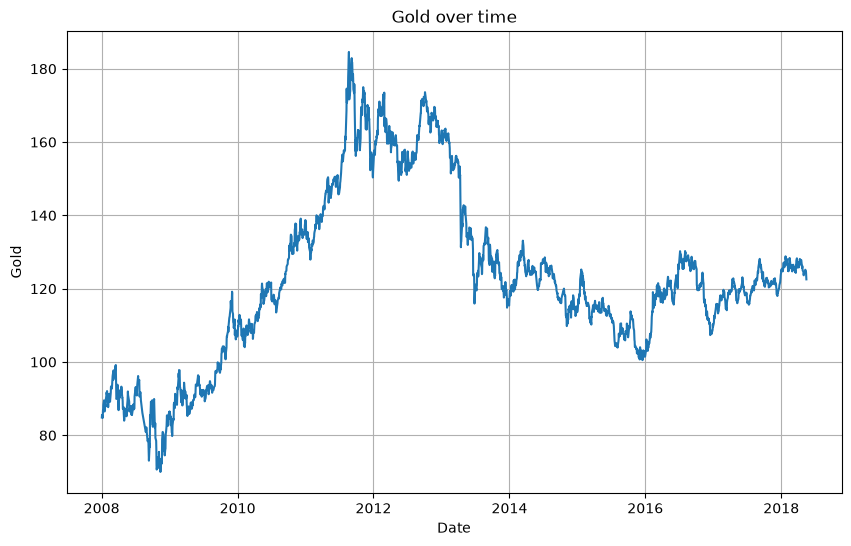

In [24]:
plt.figure(figsize=(10,6))
plt.plot(df['Date'], df['GLD'])
plt.xlabel('Date')
plt.ylabel('Gold')
plt.title('Gold over time')
plt.grid()

plt.show()

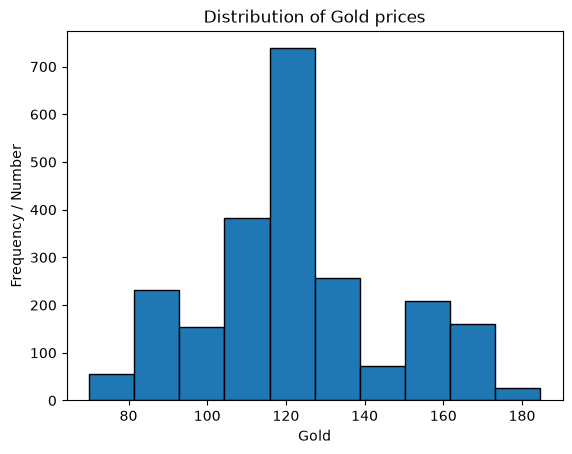

In [53]:
plt.hist( df['GLD'], edgecolor= 'black')
plt.xlabel('Gold')
plt.ylabel('Frequency / Number')
plt.title('Distribution of Gold prices')
plt.show()

C:\Users\HP\AppData\Local\Temp\ipykernel_25760\739876081.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=df['Year'],y= df['GLD'], palette="Set2")


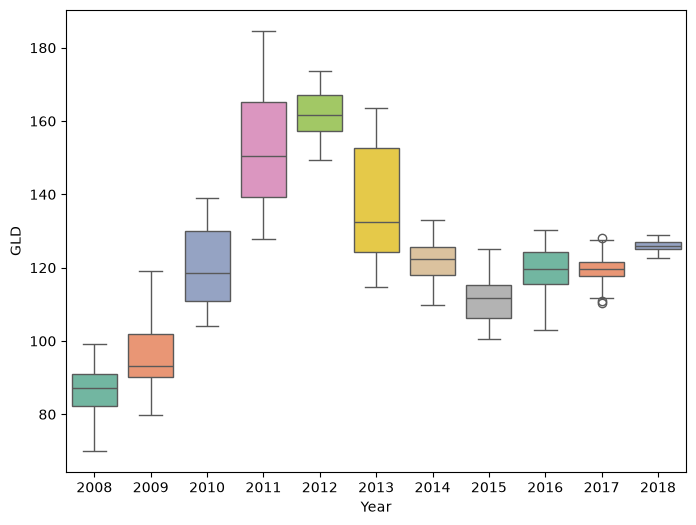

In [40]:
plt.figure(figsize=(8,6))
sns.boxplot(x=df['Year'],y= df['GLD'], palette="Set2")
plt.show()

In [45]:
corr_columns=df.select_dtypes(['int','float'])
corr_columns = corr_columns.drop(columns='Year')
corr_columns

,SPX,GLD,USO,SLV,EUR/USD
0,1447.160034,84.860001,78.470001,15.1800,1.471692
1,1447.160034,85.570000,78.370003,15.2850,1.474491
2,1411.630005,85.129997,77.309998,15.1670,1.475492
3,1416.180054,84.769997,75.500000,15.0530,1.468299
4,1390.189941,86.779999,76.059998,15.5900,1.557099
...,...,...,...,...,...
2285,2671.919922,124.589996,14.060000,15.5100,1.186789
2286,2697.790039,124.330002,14.370000,15.5300,1.184722
2287,2723.070068,125.180000,14.410000,15.7400,1.191753
2288,2730.129883,124.489998,14.380000,15.5600,1.193118


In [47]:
corr_data= corr_columns.corr()   # getting pearson correlation value
corr_data

,SPX,GLD,USO,SLV,EUR/USD
SPX,1.000000,0.049345,-0.591573,-0.274055,-0.672017
GLD,0.049345,1.000000,-0.186360,0.866632,-0.024375
USO,-0.591573,-0.186360,1.000000,0.167547,0.829317
SLV,-0.274055,0.866632,0.167547,1.000000,0.321631
EUR/USD,-0.672017,-0.024375,0.829317,0.321631,1.000000


<Axes: >

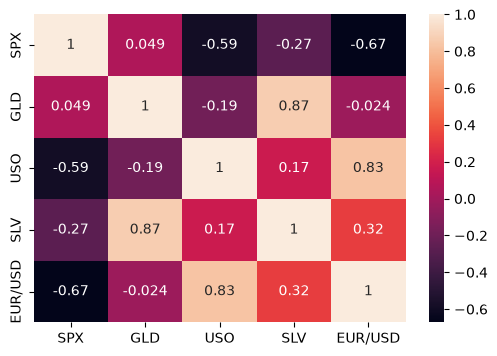

In [49]:
plt.figure(figsize=(6,4))
sns.heatmap(corr_data,annot=True)

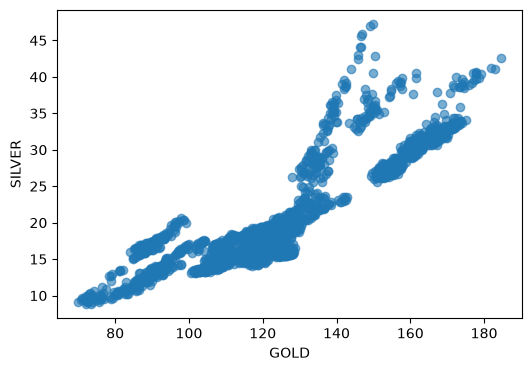

In [52]:
plt.figure(figsize=(6,4))
plt.scatter(df['GLD'],df['SLV'],alpha= 0.6)
plt.xlabel('GOLD')
plt.ylabel('SILVER')
plt.show()

In [57]:
df.columns

Index(['Date', 'SPX', 'GLD', 'USO', 'SLV', 'EUR/USD', 'Year'], dtype='str')

In [58]:
features= [ 'SPX', 'USO', 'SLV', 'EUR/USD', 'Year']
target=['GLD']

In [60]:
X= df[features]
Y= df[target]

In [62]:
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size= 0.2, random_state =42
)

In [63]:
scaler= StandardScaler()
X_train_scale= scaler.fit_transform(X_train)
X_test_scale= scaler.transform(X_test)

In [64]:
model= LinearRegression()

In [65]:
model.fit(X_train_scale,Y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1, 5)","[[-12.59, 0.88, 19.93, 0.79, 21.52]]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](1,)",[122.9]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,5
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(5)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](5,)","[79.02,41.3 ,30.12,16.63, 5.21]"


In [66]:
Y_pred = model.predict(X_test_scale)

In [69]:
mae= mean_absolute_error(Y_test,Y_pred)
mse= mean_squared_error(Y_test,Y_pred)
rmse= np.sqrt(mse)
r2=r2_score(Y_test,Y_pred)

In [70]:
print(f'Mean Absolute Error: {mae:,.2f}')
print(f'Mean Squared Error: {mse:,.2f}')
print(f'Root Mean Squared Error: {rmse:,.2f}')
print(f'R2 Score: {r2:,.2f}')

Mean Absolute Error: 5.12
Mean Squared Error: 48.32
Root Mean Squared Error: 6.95
R2 Score: 0.91


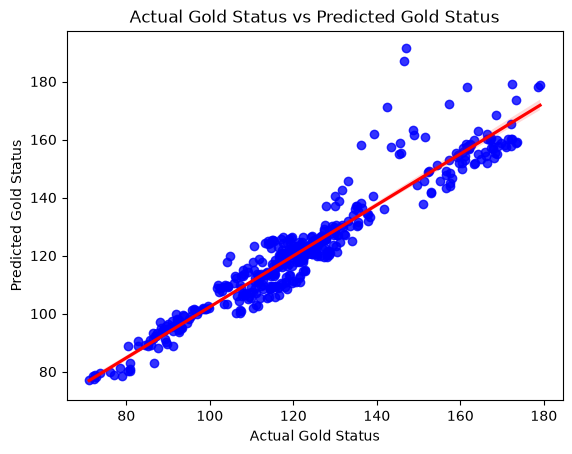

In [71]:
sns.regplot(x= Y_test, y = Y_pred, color= 'blue', line_kws={'color':'red'})
plt.xlabel('Actual Gold Status')
plt.ylabel('Predicted Gold Status')
plt.title('Actual Gold Status vs Predicted Gold Status')
plt.show()